In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/credit-card-customer-churn-prediction/Churn_Modelling.csv


In [11]:
df = pd.read_csv('/kaggle/input/credit-card-customer-churn-prediction/Churn_Modelling.csv')

In [12]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [13]:
df.drop(columns = ['RowNumber','CustomerId','Surname'],inplace=True)

In [14]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  object 
 2   Gender           10000 non-null  object 
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 859.5+ KB


In [16]:
df.duplicated().sum()

0

In [20]:
df['Exited'].value_counts()

0    7963
1    2037
Name: Exited, dtype: int64

In [21]:
df['Geography'].value_counts()

France     5014
Germany    2509
Spain      2477
Name: Geography, dtype: int64

In [22]:
df['Gender'].value_counts()

Male      5457
Female    4543
Name: Gender, dtype: int64

In [23]:
df = pd.get_dummies(df,columns=['Geography','Gender'],drop_first=True)

In [24]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [25]:
X = df.drop(columns=['Exited'])
y = df['Exited'].values

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_trf = scaler.fit_transform(X_train)
X_test_trf = scaler.transform(X_test)

In [27]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential 
from tensorflow.keras.layers import Dense

In [42]:
model = Sequential()

model.add(Dense(11,activation='relu',input_dim=11))
model.add(Dense(11,activation='sigmoid'))
model.add(Dense(1,activation='sigmoid'))

In [43]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_3 (Dense)              (None, 11)                132       
_________________________________________________________________
dense_4 (Dense)              (None, 11)                132       
_________________________________________________________________
dense_5 (Dense)              (None, 1)                 12        
Total params: 276
Trainable params: 276
Non-trainable params: 0
_________________________________________________________________


In [44]:
model.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy'])

In [45]:
history = model.fit(X_train,y_train,batch_size=50,epochs=100,verbose=1,validation_split=0.2)

Epoch 1/100
128/128 [==============================] - 1s 3ms/step - loss: 0.5567 - accuracy: 0.7827 - val_loss: 0.5272 - val_accuracy: 0.7969
Epoch 2/100
128/128 [==============================] - 0s 2ms/step - loss: 0.5154 - accuracy: 0.7958 - val_loss: 0.5108 - val_accuracy: 0.7969
Epoch 3/100
128/128 [==============================] - 0s 2ms/step - loss: 0.5072 - accuracy: 0.7958 - val_loss: 0.5064 - val_accuracy: 0.7969
Epoch 4/100
128/128 [==============================] - 0s 2ms/step - loss: 0.5043 - accuracy: 0.7958 - val_loss: 0.5037 - val_accuracy: 0.7969
Epoch 5/100
128/128 [==============================] - 0s 2ms/step - loss: 0.5031 - accuracy: 0.7958 - val_loss: 0.5047 - val_accuracy: 0.7969
Epoch 6/100
128/128 [==============================] - 0s 2ms/step - loss: 0.5020 - accuracy: 0.7958 - val_loss: 0.5029 - val_accuracy: 0.7969
Epoch 7/100
128/128 [==============================] - 0s 2ms/step - loss: 0.5020 - accuracy: 0.7958 - val_loss: 0.4986 - val_accuracy: 0.7969

In [46]:
model.layers[0].get_weights()

[array([[ 0.09014638, -0.07412563,  0.00467329, -0.33493558,  0.47940207,
          0.57802564, -0.00176816,  0.17404975,  0.30111086, -0.04190731,
          0.64440227],
        [-0.4191369 , -0.13407438, -0.38777113, -0.39535195, -0.09934055,
          0.48447314,  0.40962476, -0.3266574 ,  0.5234779 , -0.03516819,
          0.51809007],
        [-0.25641528, -0.42400524, -0.28439978,  0.15584424, -0.16137908,
          0.23925295, -0.16771002, -0.46059224,  0.16514324,  0.30308944,
         -0.26611364],
        [ 0.07315841,  0.13725205,  0.43236226,  0.0284326 ,  0.14266075,
          0.00755656,  0.13860969, -0.17320688, -0.19868937, -0.0068573 ,
         -0.3569723 ],
        [ 0.02739343,  0.50565827, -0.23644318,  0.42137247,  0.3882717 ,
          0.6144855 , -0.6159911 ,  0.28066832,  0.5645178 , -0.23782782,
          0.07735351],
        [-0.12672947,  0.17948304, -0.23867866, -0.34370658,  0.23115425,
          0.2668986 ,  0.04854991, -0.36329803,  0.14190462,  0.2643126

In [47]:
model.layers[2].get_weights()

[array([[-0.14131093],
        [ 0.37295693],
        [-0.51186275],
        [-0.07816873],
        [ 0.5626717 ],
        [-0.6373356 ],
        [-0.09257557],
        [-0.2525943 ],
        [-0.5962943 ],
        [-0.14884584],
        [-0.299042  ]], dtype=float32),
 array([-0.15754318], dtype=float32)]

In [51]:
y_pred = model.predict(X_test)

In [52]:
y_pred

array([[0.2406691 ],
       [0.2406691 ],
       [0.2406691 ],
       ...,
       [0.2406691 ],
       [0.23804611],
       [0.2406691 ]], dtype=float32)

In [53]:
y_pred = y_pred.argmax(axis=-1)

In [54]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.7975

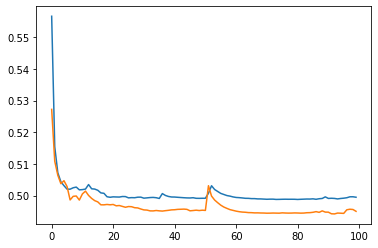

In [55]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

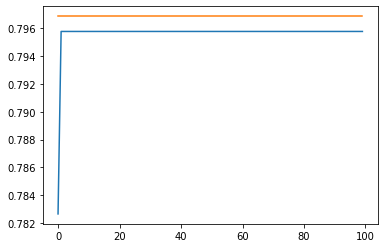

In [56]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])